# Bonus: Bakterien als Fabriken

Mit Bakterien kann man nützliche Stoffe herstellen: Medikamente wie Insulin, Kunststoffe oder Treibstoffe wie **Bioethanol**. Bioinformatikerinnen und Bioinformatiker planen mit Modellen wie unserem, welche Gene man verändern muss, damit das Bakterium so viel Produkt wie möglich herstellt.

Bisher war das Ziel „so schnell wie möglich wachsen“. Du kannst dem Modell aber auch ein anderes Ziel geben: „so viel Ethanol wie möglich herstellen“.

In [1]:
setLanguage('de')   % Sprache der Ausgaben

Sprache: Deutsch


In [2]:
model = loadEcoli();
model = setMedium(model, 10, 0);   % 10 Glukose, kein Sauerstoff

Modell geladen: E.-coli-Kernmodell mit 95 Reaktionen, 72 Metaboliten und 137 Genen.


Nahrung: Glukose-Aufnahme bis 10, Sauerstoff-Aufnahme bis 0 (mmol pro Gramm pro Stunde).


`changeObjective` ändert das Ziel. `EX_etoh_e` ist die Reaktion, die Ethanol abgibt.

In [3]:
m = changeObjective(model, 'EX_etoh_e');      % neues Ziel: so viel Ethanol wie möglich abgeben
s = optimizeCbModel(m, 'max');
biomass = s.x(strcmp(m.rxns, 'BIOMASS_Ecoli_core_w_GAM'));
fprintf('Ethanol: %.1f, Wachstum: %.3f pro Stunde\n', s.f, biomass)

Ethanol: 20.0, Wachstum: 0.000 pro Stunde


**Frage 1:** Aus 10 Glukose macht die Zelle 20 Ethanol: 2 Ethanol pro Glukose, das chemische Maximum. Aber wie schnell wächst das Bakterium jetzt? Ist das ein Problem für eine Fabrik?

✅ **Antwort:** Es wächst gar nicht (0 pro Stunde). Der ganze Zucker geht in Ethanol, für neue Zellen bleibt nichts übrig. Eine Fabrik braucht Bakterien, die auch wachsen, sonst gibt es bald keine Arbeiter mehr.

## Wachstum oder Produkt? Ein Kompromiss

Die Zelle unten zwingt das Bakterium, mindestens mit einer bestimmten Rate zu wachsen, und fragt dann, wie viel Ethanol es noch herstellen kann. Führe sie aus.

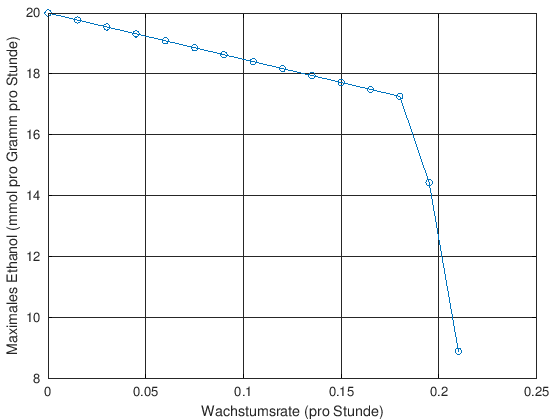

In [4]:
growth = linspace(0, 0.21, 15);                 % von keinem Wachstum bis zum Maximum ohne Sauerstoff
ethanol = zeros(size(growth));
for i = 1:numel(growth)
  m = changeRxnBounds(model, 'BIOMASS_Ecoli_core_w_GAM', growth(i), 'l');   % mindestens so schnell wachsen
  m = changeObjective(m, 'EX_etoh_e');
  s = optimizeCbModel(m, 'max');
  ethanol(i) = s.f;
end
plot(growth, ethanol, 'o-', 'linewidth', 2)
xlabel('Wachstumsrate (pro Stunde)')
ylabel('Maximales Ethanol (mmol pro Gramm pro Stunde)')
grid on

**Frage 2:** Beschreibe den Kompromiss. Wenn du eine Bioethanol-Firma hättest, welchen Punkt auf der Linie würdest du wählen, und warum?

✅ **Antwort:** Je schneller die Bakterien wachsen, desto weniger Ethanol stellen sie her. Bis zu einer Wachstumsrate von etwa 0,18 pro Stunde kostet das nur wenig Ethanol (20 → 17); danach fällt das Ethanol steil auf etwa 9 bei maximalem Wachstum. Viele würden die „Ecke“ bei etwa 0,18 wählen: Die Bakterien wachsen noch gut und stellen fast so viel Ethanol wie möglich her. Eine einzige richtige Antwort gibt es aber nicht. Eine übliche Strategie ist, die Bakterien zuerst schnell wachsen zu lassen (um viele Arbeiter zu bekommen) und sie dann auf Produktion umzuschalten. Forschende suchen auch nach Gen-Knockouts, die die Zelle zwingen, *während* des Wachstums Ethanol herzustellen.

## Dein eigenes Produkt

**Succinat** (`EX_succ_e`) wird zur Herstellung von Kunststoffen und Medikamenten verwendet. Wie viel Succinat kann *E. coli* aus 10 Glukose höchstens herstellen, ohne Sauerstoff und mit Sauerstoff? Ersetze die `___`.

In [5]:
m = changeObjective(setMedium(model, 10, 0), 'EX_succ_e');
s = optimizeCbModel(m, 'max');
fprintf('%.1f\n', s.f)
m = changeObjective(setMedium(model, 10, 1000), 'EX_succ_e');
s = optimizeCbModel(m, 'max');
fprintf('%.1f\n', s.f)

Nahrung: Glukose-Aufnahme bis 10, Sauerstoff-Aufnahme bis 0 (mmol pro Gramm pro Stunde).


13.9


Nahrung: Glukose-Aufnahme bis 10, Sauerstoff-Aufnahme bis 1000 (mmol pro Gramm pro Stunde).


16.4


✅ **Antwort:** Etwa **13,9** ohne Sauerstoff und **16,4** mit Sauerstoff. Anders als beim Ethanol hilft hier der Sauerstoff: Für Succinat braucht die Zelle zusätzliche Energie und Kohlendioxid, die sie durch Atmung leichter bekommt.

**Herzlichen Glückwunsch!** 🎉 Du hast dieselben Methoden benutzt, mit denen Forschende Bakterien untersuchen, Angriffspunkte für neue Antibiotika finden und Bakterien-Fabriken planen. Das ist Bioinformatik!

<small>Modell: *E.-coli*-Kernmodell aus BiGG Models (Orth et al. 2010; King et al. 2016). Software: COBRA Toolbox (Heirendt et al. 2019) in GNU Octave. Vollständige Quellen am Ende von `01_tutorial_fba.ipynb`.</small>